# 06 — PM2.5 exposure (Ohio counties)

**Question:** What is the average PM2.5 concentration where each county's residents live?

**Why:** Traffic produces both noise and air pollution, and PM2.5 is an established CVD risk factor. Without adjusting for it, an apparent noise effect could partly reflect air pollution.

**Data:**
- **PM2.5:** Washington University ACAG satellite-derived annual mean PM2.5, version ___, 0.01° (~1 km) grid, years 2018–2022.
- **Population locations:** building-weighted population points from notebook 04 (5,349,093 points).

**Method:**
1. Read the Ohio portion of each year's PM2.5 grid.
2. Look up PM2.5 at each population point.
3. For each county, compute the population-weighted mean PM2.5 for each year, then average across 2018–2022.

**Output:** `data/processed/pm25_oh_county.csv`: one row per county.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from rasterio.transform import rowcol

PM25_DIR      = Path("../data/large/pm25")
PEOPLE_POINTS = Path("../data/large/buildings/ohio_people_points.parquet")
PROCESSED     = Path("../data/processed")
OHIO_POP      = 11_799_448
OHIO_BOX = (-85.0, 38.2, -80.3, 42.2)   # Ohio plus a margin: west, south, east, north (degrees)

pm_files = sorted(PM25_DIR.glob("*.nc"))
for f in pm_files:
    print(f.name, f"{f.stat().st_size / 1e6:.0f} MB")
assert PEOPLE_POINTS.exists() and pm_files

V6GL02.04.CNNPM25.NA.201801-201812.nc 93 MB
V6GL02.04.CNNPM25.NA.201901-201912.nc 94 MB
V6GL02.04.CNNPM25.NA.202001-202012.nc 93 MB
V6GL02.04.CNNPM25.NA.202101-202112.nc 93 MB
V6GL02.04.CNNPM25.NA.202201-202212.nc 94 MB


In [2]:
def pm25_path(f):
    return f'NETCDF:"{f.as_posix()}":PM25'    # GDAL syntax: open the PM25 variable inside the file

with rasterio.open(pm25_path(pm_files[0])) as src:
    print("CRS:", src.crs)
    print("Cell size:", src.res)
    print("Width x height:", src.width, "x", src.height)
    print("Bounds:", src.bounds)
    print("Data type:", src.dtypes, "| NoData:", src.nodata)

CRS: None
Cell size: (0.009999999542201113, 0.010000000438763312)
Width x height: 13000 x 6000
Bounds: BoundingBox(left=-169.9999951169586, bottom=10.000000114221542, right=-40.00000106834412, top=70.00000274680141)
Data type: ('float32',) | NoData: 9.969209968386869e+36


| 0.01, 0.00,-170.00|
| 0.00,-0.01, 70.00|
| 0.00, 0.00, 1.00|
Min / max: 4.0587616 10.017224


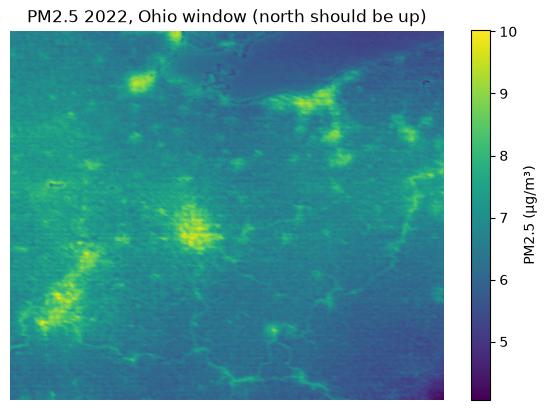

In [3]:
import matplotlib.pyplot as plt

with rasterio.open(pm25_path(pm_files[-1])) as src:
    print(src.transform)                       # the 5th number (y cell size) should be negative
    win = from_bounds(*OHIO_BOX, transform=src.transform)
    arr = src.read(1, window=win, masked=True)

print("Min / max:", arr.min(), arr.max())
plt.figure(figsize=(7, 6))
plt.imshow(arr, cmap="viridis")
plt.colorbar(label="PM2.5 (µg/m³)", shrink=0.8)
plt.title("PM2.5 2022, Ohio window (north should be up)")
plt.axis("off")
plt.show()

In [4]:
people = gpd.read_parquet(PEOPLE_POINTS)
assert np.isclose(people["pop"].sum(), OHIO_POP)

ll = people.to_crs("EPSG:4326")            # match the PM2.5 grid's lat/lon
xs, ys = ll.geometry.x.values, ll.geometry.y.values

def county_pm25(f):
    with rasterio.open(pm25_path(f)) as src:
        win = from_bounds(*OHIO_BOX, transform=src.transform)
        arr = src.read(1, window=win, masked=True).astype("float64").filled(np.nan)
        wt = src.window_transform(win)
    rows, cols = rowcol(wt, xs, ys)
    rows, cols = np.asarray(rows), np.asarray(cols)
    assert rows.min() >= 0 and cols.min() >= 0 and rows.max() < arr.shape[0] and cols.max() < arr.shape[1]
    vals = arr[rows, cols]

    ok = np.isfinite(vals)
    print(f"{f.name}: {1 - ok.mean():.4%} of points missing a value")
    df = pd.DataFrame({"county_fips": people["county_fips"].values,
                       "w": people["pop"].values * ok,
                       "wx": people["pop"].values * np.where(ok, vals, 0.0)})
    g = df.groupby("county_fips")[["w", "wx"]].sum()
    return g["wx"] / g["w"]                 # population-weighted mean PM2.5

by_year = pd.DataFrame({f.name: county_pm25(f) for f in pm_files})
by_year.columns = [c.split(".")[-2][:4] for c in by_year.columns]   # "201801-201812" -> "2018"
by_year.round(2).head()

V6GL02.04.CNNPM25.NA.201801-201812.nc: 0.0000% of points missing a value
V6GL02.04.CNNPM25.NA.201901-201912.nc: 0.0000% of points missing a value
V6GL02.04.CNNPM25.NA.202001-202012.nc: 0.0000% of points missing a value
V6GL02.04.CNNPM25.NA.202101-202112.nc: 0.0000% of points missing a value
V6GL02.04.CNNPM25.NA.202201-202212.nc: 0.0000% of points missing a value


,2018,2019,2020,2021,2022
county_fips,,,,,
39001,7.36,7.00,6.28,8.08,6.62
39003,8.50,7.97,7.34,8.42,7.81
39005,7.72,7.11,6.27,7.73,6.85
39007,6.79,6.12,5.67,6.76,6.02
39009,7.35,7.11,6.39,8.16,6.78


In [5]:
pm = by_year.mean(axis=1).rename("pm25").reset_index()

assert len(pm) == 88
assert pm["pm25"].between(2, 25).all(), pm["pm25"].describe()
print(by_year.corr().round(2))              # do counties rank the same way every year?
pm["pm25"].describe().round(2)

      2018  2019  2020  2021  2022
2018  1.00  0.91  0.92  0.85  0.90
2019  0.91  1.00  0.96  0.90  0.92
2020  0.92  0.96  1.00  0.89  0.91
2021  0.85  0.90  0.89  1.00  0.83
2022  0.90  0.92  0.91  0.83  1.00


count    88.00
mean      7.54
std       0.52
min       6.27
25%       7.17
50%       7.41
75%       7.80
max       9.30
Name: pm25, dtype: float64

In [6]:
pm.to_csv(PROCESSED / "pm25_oh_county.csv", index=False)

## Interpretation

### Findings
- Population-weighted PM2.5 was computed for all 88 counties in each year 2018–2022, using the same building-based population points as the noise exposure. All 5,349,093 points received a value in every year.
- County 2018–2022 average PM2.5:

| Statistic | µg/m³ |
|---|---|
| Median | 7.41 |
| Middle 50% of counties | 7.17 – 7.80 |
| Range | 6.27 – 9.30 |
| Standard deviation | 0.52 |

- For context, nearly all counties are below the EPA annual standard (9.0 µg/m³) but above the WHO guideline (5 µg/m³).
- The map shows higher PM2.5 in metropolitan areas (Cincinnati–Dayton, Columbus, Cleveland–Akron, Toledo) and along the Ohio River valley.

### Stability across years
- County rankings are highly consistent from year to year (r = 0.83–0.96). Levels shift (2020 lower, 2021 higher), but the same counties stay relatively more or less polluted.
- 2021 agrees least with other years (r = 0.83–0.90). Averaging over five years smooths out unusual years like this, leaving the stable geographic pattern relevant to long-term exposure.

### Implications for the model
- PM2.5 varies little across Ohio counties (SD 0.52 µg/m³), so its own coefficient is likely to be imprecise. Its role is to adjust the noise estimate for air pollution.
- PM2.5 effects will be reported per IQR (0.63 µg/m³) or per 1 µg/m³, not per 10 µg/m³, which would exceed the full range across counties.
- Urban PM2.5 hotspots overlap with noise exposure, so collinearity between PM2.5, noise, and % urban will be checked (VIFs) in notebook 07.

### Output
`data/processed/pm25_oh_county.csv`: one row per county (2018–2022 average PM2.5).